# Resultados do aprendizado por reforço no dimensionamento da frota

Este notebook resume o experimento registrado em `rl_resultados`: política **DQN (RL)**, baseline **Busca Binária do Digital Twin** e frota **Estático 60**, avaliados em cinco seeds. A pergunta central é: **qual é o compromisso entre qualidade do serviço e tamanho da frota?**

> O material disponível implementa aprendizado por reforço, não aprendizado federado. Os gráficos usam os resultados já exportados; não repetem o treino nem a simulação.

## Como ler

- **MMT**: tempo médio de missão por entrega, em minutos.
- **SLA**: percentual de entregas dentro de 80 minutos.
- As barras de erro representam desvio-padrão entre seeds (n=5), quando o dado por seed está disponível. Não representam intervalo de confiança.
- Valores agregados são médias das cinco execuções; diferenças pequenas devem ser lidas com cautela.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Funciona com o diretório de trabalho na raiz do projeto ou dentro de rl/.
CANDIDATAS = [Path.cwd() / 'rl' / 'rl_resultados', Path.cwd() / 'rl_resultados']
DADOS = next((p for p in CANDIDATAS if (p / 'resumo_comparacao_rl.csv').exists()), None)
if DADOS is None:
    raise FileNotFoundError('Não encontrei rl_resultados/resumo_comparacao_rl.csv. Abra o notebook a partir da pasta do projeto ou de rl/.')

resumo = pd.read_csv(DADOS / 'resumo_comparacao_rl.csv', sep=';', decimal=',')
rotulos = {'BuscaBinariaDT': 'Busca Binária (DT)', 'Estatico60': 'Estático (60)', 'RL': 'DQN (RL)'}
cores = {'BuscaBinariaDT': '#4C78A8', 'Estatico60': '#9AA0A6', 'RL': '#F28E2B'}
ordem = ['Estatico60', 'RL', 'BuscaBinariaDT']
resumo['Politica'] = pd.Categorical(resumo['Politica'], ordem, ordered=True)
resumo = resumo.sort_values('Politica').reset_index(drop=True)

# Séries finais por execução; o resumo oficial é a fonte para médias agregadas.
series = []
for politica in ['RL', 'BuscaBinariaDT', 'Estatico60']:
    prefixo = {'RL':'RL', 'BuscaBinariaDT':'BuscaBinariaDT', 'Estatico60':'Estatico60'}[politica]
    for seed in [1, 2, 3, 5, 7]:
        arq = DADOS / f'serie_{prefixo}_seed{seed}.csv'
        if arq.exists():
            df = pd.read_csv(arq)
            df['Politica'] = politica
            df['Seed'] = seed
            series.append(df)
series = pd.concat(series, ignore_index=True) if series else pd.DataFrame()
print(f'Diretório dos resultados: {DADOS.resolve()}')
print(f'Políticas no resumo: {len(resumo)} | Execuções carregadas: {series.groupby("Politica").size().to_dict() if not series.empty else "nenhuma"}')


Diretório dos resultados: /home/callmepeh/Área de trabalho/PASID2/drone-delivery-sim-master-versao3(1)/drone-delivery-sim-master-versao3/rl/rl_resultados
Políticas no resumo: 3 | Execuções carregadas: {'BuscaBinariaDT': 1200, 'Estatico60': 1200, 'RL': 1200}


## 1. Desempenho e custo: resumo direto

O primeiro gráfico coloca SLA e MMT lado a lado: mais SLA e menos MMT são melhores. O gráfico de frota mostra o custo operacional médio. Os números são médias entre cinco seeds.


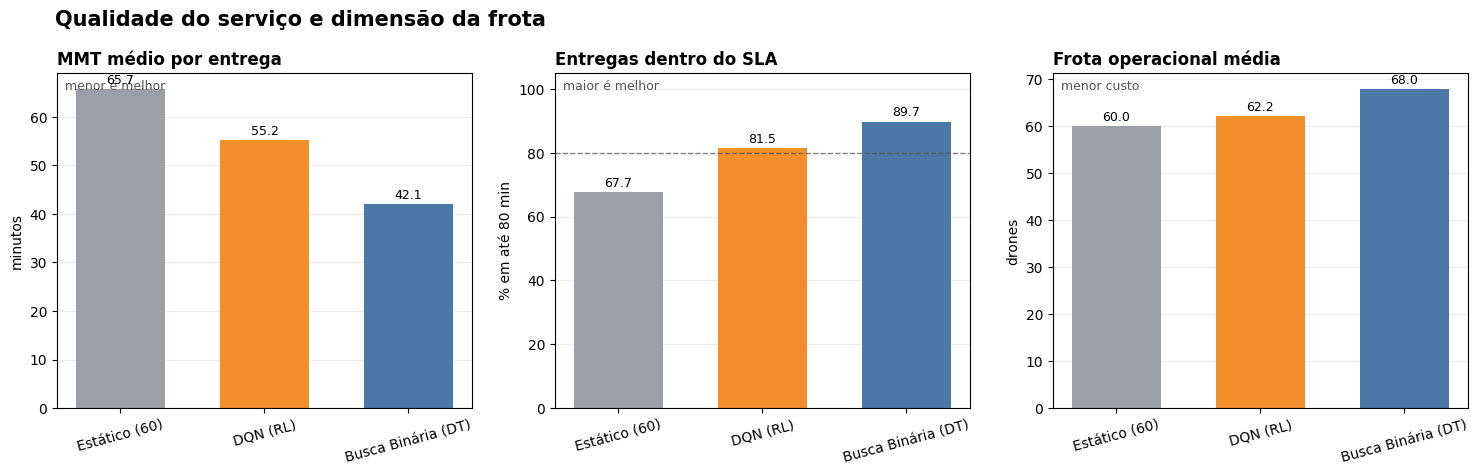

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
campos = [
    ('MMT_med(min)', 'MMT médio por entrega', 'minutos', 'menor é melhor'),
    ('SLA_ok(%)', 'Entregas dentro do SLA', '% em até 80 min', 'maior é melhor'),
    ('Frota_media', 'Frota operacional média', 'drones', 'menor custo'),
]
for ax, (col, titulo, eixo, nota) in zip(axes, campos):
    d = resumo.dropna(subset=[col]).sort_values('Politica')
    bars = ax.bar([rotulos[str(x)] for x in d['Politica']], d[col],
                  color=[cores[str(x)] for x in d['Politica']], width=.62)
    ax.set_title(titulo, loc='left', weight='bold')
    ax.set_ylabel(eixo)
    ax.text(.02, .98, nota, transform=ax.transAxes, va='top', color='#555', fontsize=9)
    ax.grid(axis='y', alpha=.22); ax.set_axisbelow(True)
    ax.tick_params(axis='x', rotation=15)
    for b, v in zip(bars, d[col]):
        ax.annotate(f'{v:.1f}', (b.get_x()+b.get_width()/2, b.get_height()), xytext=(0,4),
                    textcoords='offset points', ha='center', fontsize=9)
axes[1].axhline(80, color='#555', ls='--', lw=1, alpha=.7)
axes[1].set_ylim(0, 105)
fig.suptitle('Qualidade do serviço e dimensão da frota', x=.04, ha='left', fontsize=15, weight='bold')
fig.tight_layout()
plt.show()


## 2. Compromisso entre SLA e frota

Cada ponto é uma política. O canto superior esquerdo (SLA alto, frota baixa) é preferível. A anotação de MMT ajuda a interpretar a qualidade de serviço.


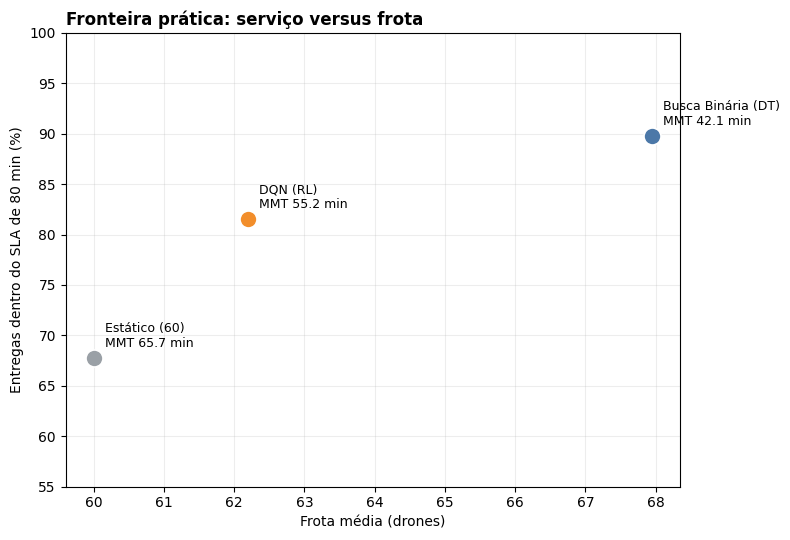

In [3]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for _, r in resumo.iterrows():
    pol = str(r['Politica'])
    x, y = r['Frota_media'], r['SLA_ok(%)']
    ax.scatter(x, y, s=150, color=cores[pol], edgecolor='white', linewidth=1.2, zorder=3)
    ax.annotate(f'{rotulos[pol]}\nMMT {r["MMT_med(min)"]:.1f} min', (x,y), xytext=(8,8),
                textcoords='offset points', fontsize=9)
ax.set_xlabel('Frota média (drones)'); ax.set_ylabel('Entregas dentro do SLA de 80 min (%)')
ax.set_title('Fronteira prática: serviço versus frota', loc='left', weight='bold')
ax.grid(alpha=.22); ax.set_axisbelow(True); ax.set_ylim(55, 100)
fig.tight_layout(); plt.show()


## 3. Variação entre seeds

As séries por seed contêm a trajetória de estado, mas não os indicadores finais por entrega. Por isso, a dispersão abaixo mostra **a variabilidade temporal das séries** (`MMTEwma` e `Fila`) ao longo do horizonte, agregando snapshots e seeds. Ela complementa, mas não substitui, a comparação estatística de resultados finais.


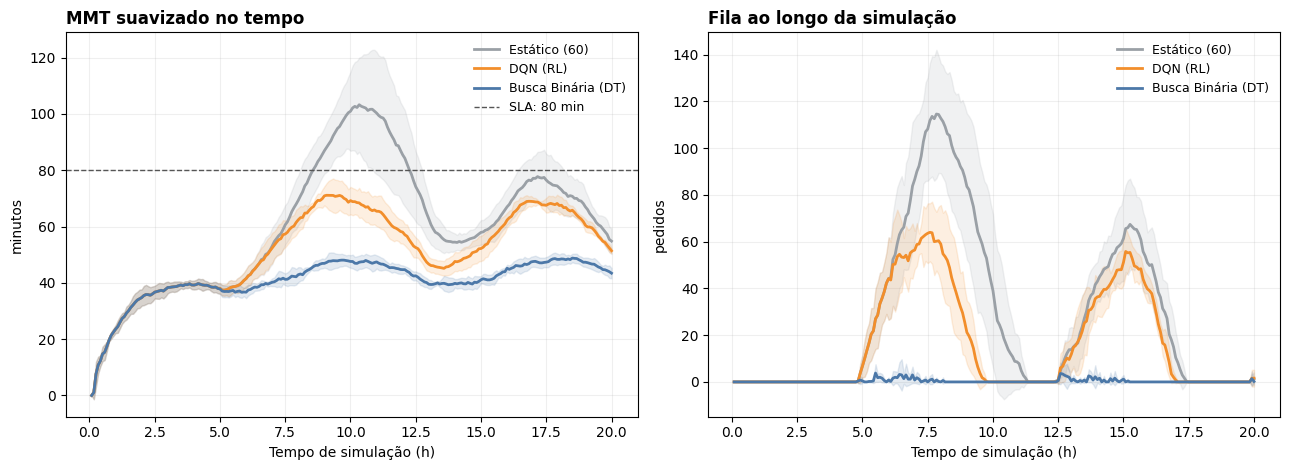

In [4]:
if not series.empty:
    series['Tempo_h'] = series['Time(ms)'] / 3_600_000
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    for pol in ['Estatico60', 'RL', 'BuscaBinariaDT']:
        d = series[series['Politica'] == pol]
        cor = cores[pol]
        for ax, col, title, ylabel in [
            (axes[0], 'MMTEwma(min)', 'MMT suavizado no tempo', 'minutos'),
            (axes[1], 'Fila', 'Fila ao longo da simulação', 'pedidos'),
        ]:
            if col not in d: continue
            g = d.groupby('Tempo_h')[col].agg(['mean','std']).dropna()
            ax.plot(g.index, g['mean'], color=cor, lw=2, label=rotulos[pol])
            ax.fill_between(g.index, g['mean']-g['std'], g['mean']+g['std'], color=cor, alpha=.14)
            ax.set_title(title, loc='left', weight='bold'); ax.set_xlabel('Tempo de simulação (h)'); ax.set_ylabel(ylabel)
            ax.grid(alpha=.2); ax.set_axisbelow(True)
    axes[0].axhline(80, color='#555', ls='--', lw=1, label='SLA: 80 min')
    axes[0].legend(frameon=False, fontsize=9); axes[1].legend(frameon=False, fontsize=9)
    fig.tight_layout(); plt.show()
else:
    print('Séries por seed não encontradas; gráfico temporal não foi gerado.')


## 4. Evolução do treino DQN

A recompensa por episódio é a medida que o agente otimizou durante o treino. A média móvel suaviza a oscilação episódio a episódio; ela não é diretamente equivalente a SLA ou MMT.


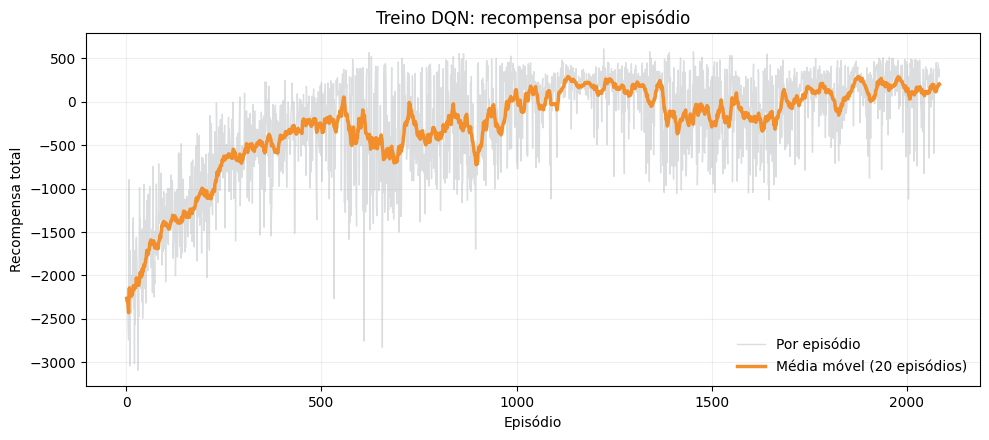

In [5]:
treino_path = DADOS / 'treino_dqn.csv'
if treino_path.exists():
    treino = pd.read_csv(treino_path)
    treino['Recompensa móvel (20 eps)'] = treino['recompensa_total'].rolling(20, min_periods=1).mean()
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.plot(treino['episodio'], treino['recompensa_total'], color='#9AA0A6', alpha=.35, lw=1, label='Por episódio')
    ax.plot(treino['episodio'], treino['Recompensa móvel (20 eps)'], color='#F28E2B', lw=2.5, label='Média móvel (20 episódios)')
    ax.set(title='Treino DQN: recompensa por episódio', xlabel='Episódio', ylabel='Recompensa total')
    ax.grid(alpha=.2); ax.legend(frameon=False); fig.tight_layout(); plt.show()
else:
    print('Log treino_dqn.csv não encontrado.')


## 5. Tabela para consulta


In [6]:
colunas = ['Politica','Entregas','MMT_med(min)','MMT_mediano(min)','MMT_P95(min)','SLA_ok(%)','Q_fila_media','Frota_media','Aluguel_drone_h','E_Consu(Wh)','Decisao_CPU_med(ms)']
tabela = resumo[colunas].copy()
tabela['Politica'] = tabela['Politica'].astype(str).map(rotulos)
tabela = tabela.rename(columns={
    'Politica':'Política','Entregas':'Entregas','MMT_med(min)':'MMT médio (min)',
    'MMT_mediano(min)':'MMT mediano (min)','MMT_P95(min)':'MMT P95 (min)',
    'SLA_ok(%)':'SLA ok (%)','Q_fila_media':'Fila média','Frota_media':'Frota média',
    'Aluguel_drone_h':'Aluguel (drone-h)','E_Consu(Wh)':'Energia (Wh)',
    'Decisao_CPU_med(ms)':'CPU por decisão (ms)'})
display(tabela.round(2))


,Política,Entregas,MMT médio (min),MMT mediano (min),MMT P95 (min),SLA ok (%),Fila média,Frota média,Aluguel (drone-h),Energia (Wh),CPU por decisão (ms)
0,Estático (60),1366.8,65.74,59.96,134.61,67.74,27.88,60.00,0.00,111076.0,0.00
1,DQN (RL),1368.6,55.24,51.11,113.10,81.50,16.38,62.20,44.00,110181.0,0.17
2,Busca Binária (DT),1367.2,42.10,35.17,97.21,89.72,0.34,67.95,158.98,112735.0,0.04


## Síntese

Com os resultados agregados atuais, a **RL melhora o SLA em relação à frota estática** (81,5% vs. 67,7%) com frota média de 62,2 drones (vs. 60,0), e reduz fila média (16,4 vs. 27,9). A **Busca Binária** entrega o melhor MMT e SLA (42,1 min; 89,7%), usando frota média maior (68,0) e mais horas de aluguel. Assim, a RL ocupa um ponto intermediário entre serviço e custo.

A decisão CPU mediana da RL é maior que a dos baselines no log (0,175 ms); ainda assim, esse custo isolado é pequeno frente ao horizonte da simulação. As conclusões valem para os cenários, parâmetros e cinco seeds já avaliados e não provam generalização para outras demandas.
